In [1]:
!pip install -q jiwer librosa soundfile

import os, random, importlib.metadata as md
import numpy as np, torch
from google.colab import drive
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# ---- settings shared by the later cells ----
SEED = 42
DATA = "/content/drive/MyDrive/Mfasha chatbot/data"
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# ---- Google Drive, with a check that it is the right account ----
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")
if not os.path.isdir(DATA):
    print("WARNING: this folder did not exist, so an empty one is being created.",
          "Check the Google account at the top right of the page.")
os.makedirs(DATA, exist_ok=True)
print("Drive folder:", DATA, "|", len(os.listdir(DATA)), "files")
need = ["chunks.jsonl", "kinya-retriever-e5", "mms_kin_adapter_finetuned.pt"]
print("project files found:", {f: os.path.exists(f"{DATA}/{f}") for f in need})

# Hugging Face token
HF_TOKEN = None
try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    pass
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
print("HF token found:", bool(HF_TOKEN), "(not needed, but downloads are faster with one)")

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none: set Runtime > Change runtime type > T4 GPU")
print("versions:", {p: md.version(p) for p in ["torch", "transformers", "jiwer", "librosa"]})

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 59.6 MB/s eta 0:00:00
Mounted at /content/drive
Drive folder: /content/drive/MyDrive/Mfasha chatbot/data | 41 files
project files found: {'chunks.jsonl': True, 'kinya-retriever-e5': True, 'mms_kin_adapter_finetuned.pt': True}
HF token found: False (not needed, but downloads are faster with one)
GPU: Tesla T4
versions: {'torch': '2.11.0+cu130', 'transformers': '5.18.0', 'jiwer': '4.0.0', 'librosa': '0.11.0'}


In [4]:
!pip install -q qdrant-client rank_bm25 sentence-transformers

import sys, time, collections
import numpy as np
from transformers import Wav2Vec2ForCTC, AutoProcessor

assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU, then run Cell 1 again"
DEVICE = "cuda"

#  speech recognition: Meta MMS with the Kinyarwanda adapter
ASR_ID = "facebook/mms-1b-all"
ADAPTER_FILE = f"{DATA}/mms_kin_adapter_finetuned.pt"

processor = AutoProcessor.from_pretrained(ASR_ID, target_lang="kin")
asr_model = Wav2Vec2ForCTC.from_pretrained(ASR_ID, target_lang="kin", ignore_mismatched_sizes=True).to(DEVICE)
asr_model.eval()

orig_state = {n: p.detach().cpu().clone() for n, p in asr_model.named_parameters()
              if "adapter_layer" in n or n.startswith("lm_head")}           # the original adapter
ft_state = torch.load(ADAPTER_FILE, map_location="cpu") if os.path.exists(ADAPTER_FILE) else None

def use_adapter(which):
    """which = 'original' or 'finetuned'"""
    state = orig_state if which == "original" else ft_state
    assert state is not None, "the fine-tuned adapter file was not found in your Drive data folder"
    with torch.no_grad():
        for n, p in asr_model.named_parameters():
            if n in state:
                p.copy_(state[n].to(p.device))
    asr_model.eval()
    print("active speech adapter:", which)

def transcribe(audio, sr=16000):
    """audio: 1-D float array at 16 kHz."""
    inputs = processor(audio, sampling_rate=sr, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        logits = asr_model(**inputs).logits
    return processor.decode(torch.argmax(logits, dim=-1)[0]).strip()

t0 = time.time()
print("speech test on silence ->", repr(transcribe(np.zeros(16000, dtype=np.float32))), "| %.1f s" % (time.time() - t0))
print("speech model on", DEVICE, "| %.0f million weights" % (sum(p.numel() for p in asr_model.parameters()) / 1e6),
      "| fine-tuned adapter file found:", ft_state is not None, "| active adapter: original")

# the chatbot's search: the same chatbot.py as the web app
bot = None
sys.path.insert(0, DATA)
try:
    import chatbot as cb
    from sentence_transformers import SentenceTransformer
    retriever = SentenceTransformer(f"{DATA}/kinya-retriever-e5", device=DEVICE)
    retriever.max_seq_length = 256
    bot = cb.Chatbot(chunks_path=f"{DATA}/chunks.jsonl", emb_path=f"{DATA}/chunk_emb_e5.npy", model=retriever)
    r = bot.ask("soya ihunikwa ahantu hameze gute ?")
    print("chatbot ready:", len(bot.chunks), "chunks | typed test question -> confidence %.2f, level %s, passage %s"
          % (r["confidence"], r["tier"], r["passage_id"]))
except ModuleNotFoundError as e:
    if e.name != "chatbot":
        raise
    print("chatbot.py is not in your Drive data folder. Upload src/chatbot.py from your laptop to:", DATA, "then run this cell again.")

#  speech meets the chatbot
def voice_ask(audio, sr=16000):
    """spoken question (16 kHz array) -> (text the model heard, the chatbot's answer)"""
    heard = transcribe(audio, sr)
    return heard, (bot.ask(heard) if bot else None)

speech test on silence -> '' | 4.2 s
speech model on cuda | 965 million weights | fine-tuned adapter file found: True | active adapter: original
chatbot.py is not in your Drive data folder. Upload src/chatbot.py from your laptop to: /content/drive/MyDrive/Mfasha chatbot/data then run this cell again.


In [5]:
import re, collections
import pandas as pd
from huggingface_hub import list_repo_files, hf_hub_download

DS_ID = "C4IR-RW/kinya-ag-tts"
files = list_repo_files(DS_ID, repo_type="dataset")
audio = [f for f in files if f.lower().endswith(".wav")]
wav_set = set(audio)
print("audio files:", len(audio), "|", dict(collections.Counter(f.split("/")[0] for f in audio)))

def has_digit(t):
    return any(ch.isdigit() for ch in t)

def key_of(t):                      # used for the split. Do NOT change it: it keeps your saved split valid
    return re.sub(r"\s+", " ", t.strip().lower())

def nkey_of(t):                     # stricter key: ignores punctuation and apostrophes, to find near-duplicates
    t = t.lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t).replace("'", "")
    return re.sub(r"\s+", " ", t).strip()

def messy(t):                       # text a speech model cannot be expected to match exactly
    return bool(re.search(r"[()/\[\]]", t)) or any(ord(ch) > 127 and ch not in "\u2019\u2018" for ch in t)

tables = {}
for tsv in sorted(f for f in files if f.endswith(".tsv")):
    path = hf_hub_download(DS_ID, tsv, repo_type="dataset")
    raw = pd.read_csv(path, sep="\t", header=None, quoting=3, dtype=str,
                      keep_default_na=False, on_bad_lines="skip")
    df = raw.iloc[:, :2].copy()
    df.columns = ["id", "text"]
    df["id"] = df["id"].str.replace(".wav", "", regex=False).str.strip()
    folder = tsv[:-4]
    df["wav"] = folder + "/" + df["id"] + ".wav"
    df["has_wav"] = df["wav"].isin(wav_set)
    tables[folder] = df
    print(f"{folder:20s} rows {len(df):5d} | audio found {int(df.has_wav.sum()):5d} | no digits {100*(~df.text.apply(has_digit)).mean():.0f}%")

allrows = pd.concat([d.assign(set=n) for n, d in tables.items()], ignore_index=True)
allrows["key"] = allrows.text.apply(key_of)
allrows["nkey"] = allrows.text.apply(nkey_of)
allrows["messy"] = allrows.text.apply(messy)

ok = allrows[allrows.has_wav]
per = ok.groupby("key")["set"].nunique()
print("\nusable clips:", len(ok))
print("different sentences by exact text        :", ok.key.nunique())
print("different sentences ignoring punctuation :", ok.nkey.nunique())
print("sentences read in 1 / 2 / 3 or more sets :", int((per == 1).sum()), "/", int((per == 2).sum()), "/", int((per >= 3).sum()))

dup = ok.groupby("nkey")["key"].nunique()
risky = dup[dup > 1].index
print("\nsentences written in several ways        :", len(risky), "| clips affected:", int(ok.nkey.isin(risky).sum()))
print("texts with brackets, slashes or foreign letters: %.1f%%" % (100 * ok.messy.mean()))

audio files: 17972 | {'rw_ag_tts_female': 5239, 'rw_ag_tts_female2': 3830, 'rw_ag_tts_male': 5243, 'rw_ag_tts_male2': 3660}
rw_ag_tts_female     rows  5242 | audio found  5227 | no digits 76%
rw_ag_tts_female2    rows  3830 | audio found  3830 | no digits 77%
rw_ag_tts_male       rows  5238 | audio found  5231 | no digits 76%
rw_ag_tts_male2      rows  3659 | audio found  3658 | no digits 77%

usable clips: 17946
different sentences by exact text        : 5240
different sentences ignoring punctuation : 5128
sentences read in 1 / 2 / 3 or more sets : 9 / 1429 / 3802

sentences written in several ways        : 105 | clips affected: 641
texts with brackets, slashes or foreign letters: 20.3%


In [6]:
import random, time, io, pickle, os
import numpy as np, librosa, requests, soundfile as sf
from concurrent.futures import ThreadPoolExecutor

N_TRAIN, N_DEV, N_TEST = 1000, 60, 200       # number of different SENTENCES
PER_SENT = 2                                  # recordings kept per sentence
MAX_WORDS, MAX_SEC = 40, 20

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = None
print("HF token found:", bool(HF_TOKEN), "(without one it still works, but slower)")

pool = allrows[allrows.has_wav & (allrows.text.str.strip().str.len() > 10)
               & (~allrows.text.apply(has_digit)) & (allrows.text.str.split().str.len() <= MAX_WORDS)].copy()
keys = sorted(pool.key.unique())
random.Random(42).shuffle(keys)
test_k  = set(keys[:N_TEST])
dev_k   = set(keys[N_TEST:N_TEST + N_DEV])
train_k = set(keys[N_TEST + N_DEV:N_TEST + N_DEV + N_TRAIN])
assert not (train_k & test_k) and not (train_k & dev_k) and not (dev_k & test_k)

pool["split"] = pool.key.map(lambda k: "test" if k in test_k else "dev" if k in dev_k else "train" if k in train_k else None)
use = pool[pool.split.notna()].sample(frac=1, random_state=42).groupby("key").head(PER_SENT).reset_index(drop=True)
print("clips chosen:", len(use), "|", use.split.value_counts().to_dict())

CACHE = f"{DATA}/asr_cache_{N_TRAIN}_{N_DEV}_{N_TEST}_{PER_SENT}.pkl"
if os.path.exists(CACHE):
    print("loading the saved audio from Drive...")
    with open(CACHE, "rb") as f:
        saved = pickle.load(f)
    data = {s: [{**c, "audio": c["audio"].astype(np.float32) / 32768.0} for c in v] for s, v in saved.items()}
else:
    HEAD = {"Authorization": f"Bearer {HF_TOKEN}"} if HF_TOKEN else {}
    BASE = f"https://huggingface.co/datasets/{DS_ID}/resolve/main/"
    sess = requests.Session()
    done = [0]

    def fetch(path):
        for attempt in range(8):
            try:
                r = sess.get(BASE + path, headers=HEAD, timeout=60)
                if r.status_code == 429:
                    time.sleep(min(int(r.headers.get("Retry-After", 20)), 120))
                    continue
                r.raise_for_status()
                y, sr = sf.read(io.BytesIO(r.content), dtype="float32")
                if y.ndim > 1:
                    y = y.mean(1)
                if sr != 16000:
                    y = librosa.resample(y, orig_sr=sr, target_sr=16000)
                done[0] += 1
                if done[0] % 300 == 0:
                    print("  downloaded", done[0], "of", len(use), "| %.0f s" % (time.time() - t0))
                return y
            except Exception:
                time.sleep(2 * (attempt + 1))
        return None

    t0 = time.time()
    with ThreadPoolExecutor(6 if HF_TOKEN else 3) as ex:
        audios = list(ex.map(fetch, use.wav))
    print("download finished in %.0f s" % (time.time() - t0))

    data = {"train": [], "dev": [], "test": []}
    skipped = 0
    for (_, r), y in zip(use.iterrows(), audios):
        if y is None or len(y) / 16000 > MAX_SEC or len(y) < 1600:
            skipped += 1
            continue
        data[r["split"]].append({"audio": y, "text": r["text"], "set": r["set"], "id": r["id"], "key": r["key"]})
    print("skipped (failed, too long or too short):", skipped)
    if skipped > 0.3 * len(use):
        print("WARNING: many clips failed. Add the HF_TOKEN secret, wait 5 minutes, and run this cell again.")

    to_save = {s: [{**c, "audio": (np.clip(c["audio"], -1, 1) * 32767).astype(np.int16)} for c in v] for s, v in data.items()}
    with open(CACHE, "wb") as f:
        pickle.dump(to_save, f)
    print("saved the audio to Drive:", os.path.basename(CACHE))

for s, items in data.items():
    hours = sum(len(c["audio"]) for c in items) / 16000 / 3600
    print(f"{s:5s}: {len(items):5d} clips | {len({c['key'] for c in items}):5d} different sentences | {hours:.2f} hours")
assert not ({c["key"] for c in data["train"]} & {c["key"] for c in data["test"]}), "sentence overlap between train and test"
print("checked: no sentence appears in both train and test")

pd.DataFrame([{"split": s, "set": c["set"], "id": c["id"], "text": c["text"]} for s, v in data.items() for c in v]) \
  .to_csv(f"{DATA}/asr_split.csv", index=False, encoding="utf-8-sig")

HF token found: False (without one it still works, but slower)
clips chosen: 2518 | {'train': 2000, 'test': 398, 'dev': 120}
loading the saved audio from Drive...
train:  2000 clips |  1000 different sentences | 2.58 hours
dev  :   120 clips |    60 different sentences | 0.16 hours
test :   398 clips |   200 different sentences | 0.55 hours
checked: no sentence appears in both train and test


In [7]:
for s in data:
    for c in data[s]:
        c["nkey"] = nkey_of(c["text"])
        c["messy"] = messy(c["text"])

train_n = {c["nkey"] for c in data["train"]}

print("clips whose sentence (ignoring punctuation) is also in TRAIN:")
for s in ["dev", "test"]:
    hit = sum(c["nkey"] in train_n for c in data[s])
    print(f"  {s:4s}: {hit} of {len(data[s])} clips ({100 * hit / len(data[s]):.1f}%)")

print("\nclips with brackets, slashes or foreign letters:")
for s in data:
    m = sum(c["messy"] for c in data[s])
    print(f"  {s:5s}: {m} of {len(data[s])} ({100 * m / len(data[s]):.1f}%)")

ex = sorted({c["text"] for c in data["test"] if c["nkey"] in train_n})[:5]
print("\nexamples of test sentences that are also in train:", ex if ex else "none")

clips whose sentence (ignoring punctuation) is also in TRAIN:
  dev : 4 of 120 clips (3.3%)
  test: 2 of 398 clips (0.5%)

clips with brackets, slashes or foreign letters:
  train: 318 of 2000 (15.9%)
  dev  : 16 of 120 (13.3%)
  test : 70 of 398 (17.6%)

examples of test sentences that are also in train: ['Gusimburanya neza ibihingwa,']


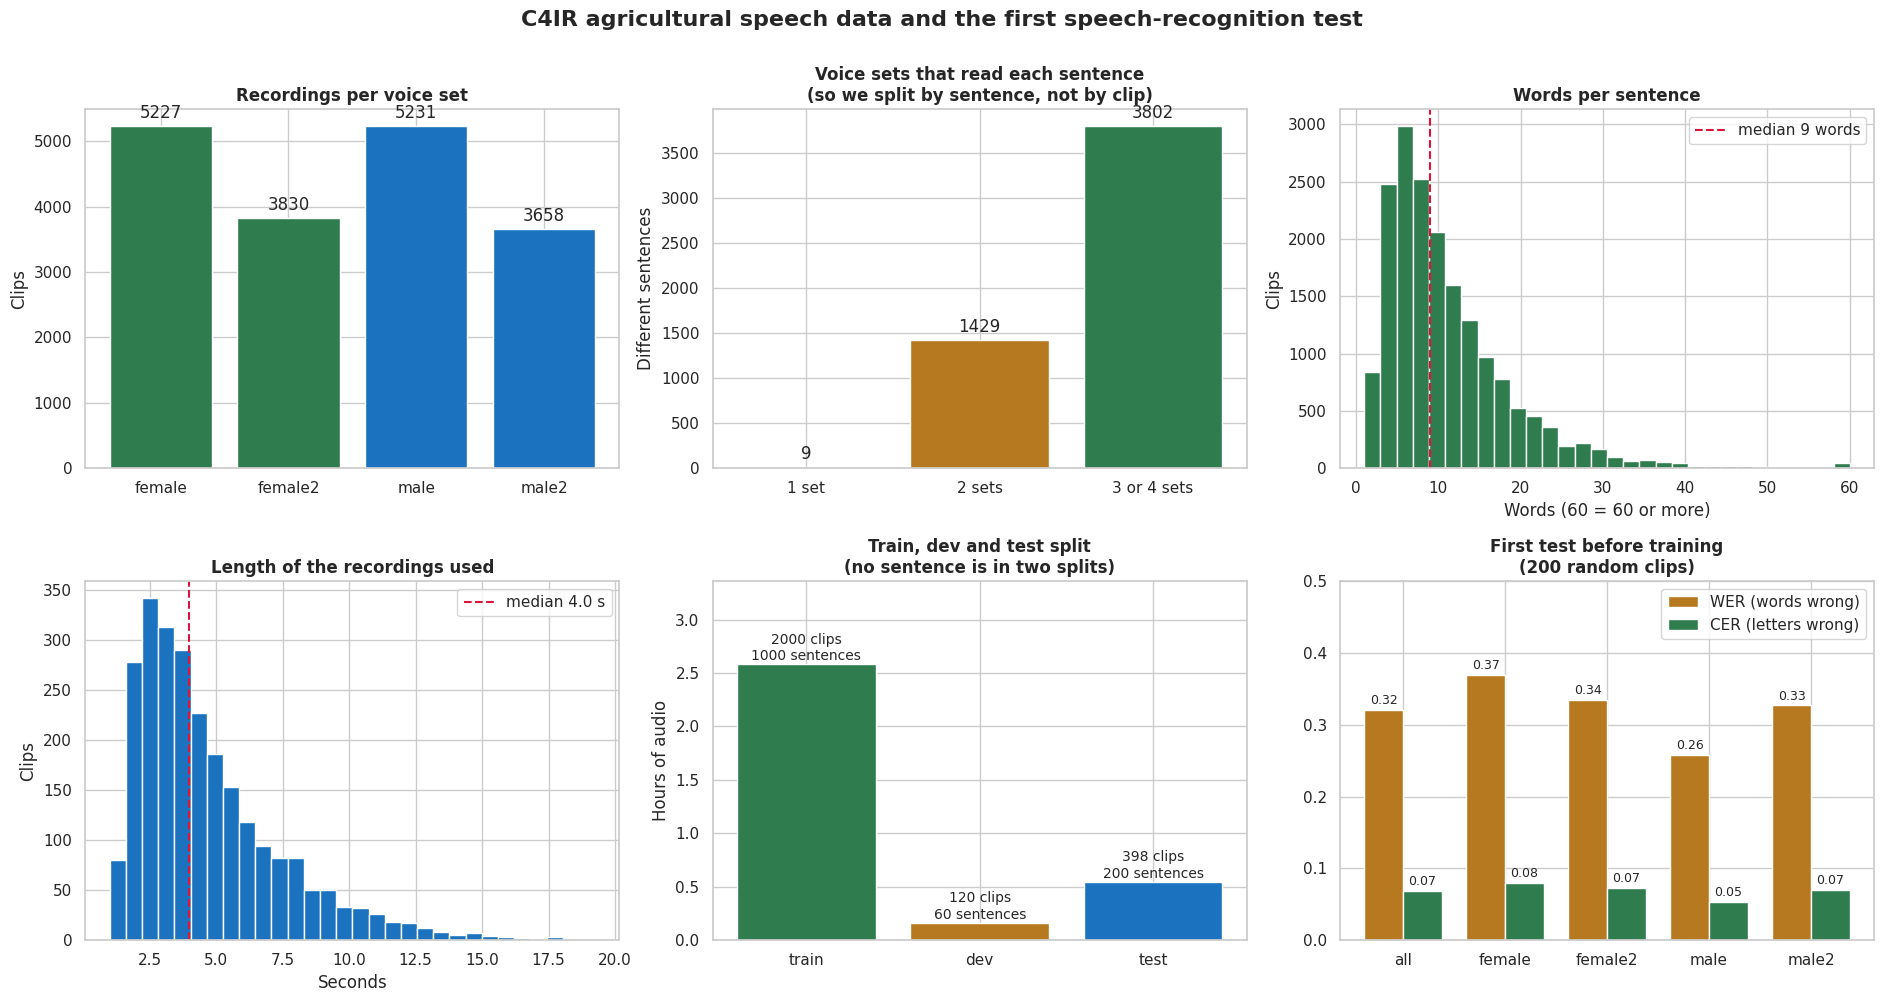

saved to Drive: asr_data_overview.png
sentences with digits: 24%


In [8]:
import matplotlib.pyplot as plt, seaborn as sns, numpy as np, pandas as pd
sns.set_theme(style="whitegrid")
GREEN, BLUE, AMBER, GREY = "#2f7d4f", "#1b73c0", "#b7791f", "#98a2b3"
short = lambda s: s.replace("rw_ag_tts_", "")

ok = allrows[allrows.has_wav]
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

# clips per voice set
cnt = ok.groupby("set").size()
bars = ax[0, 0].bar([short(s) for s in cnt.index], cnt.values,
                    color=[GREEN if "female" in s else BLUE for s in cnt.index])
ax[0, 0].bar_label(bars, fmt="%d", padding=3)
ax[0, 0].set_title("Recordings per voice set", fontweight="bold")
ax[0, 0].set_ylabel("Clips")

# how many voice sets read each sentence
per = ok.groupby("key")["set"].nunique()
vals = [int((per == 1).sum()), int((per == 2).sum()), int((per >= 3).sum())]
bars = ax[0, 1].bar(["1 set", "2 sets", "3 or 4 sets"], vals, color=[GREY, AMBER, GREEN])
ax[0, 1].bar_label(bars, fmt="%d", padding=3)
ax[0, 1].set_title("Voice sets that read each sentence\n(so we split by sentence, not by clip)", fontweight="bold")
ax[0, 1].set_ylabel("Different sentences")

# words per sentence
words = ok.text.str.split().str.len().clip(upper=60)
ax[0, 2].hist(words, bins=30, color=GREEN, edgecolor="white")
ax[0, 2].axvline(words.median(), color="crimson", linestyle="--", label=f"median {int(words.median())} words")
ax[0, 2].set_title("Words per sentence", fontweight="bold")
ax[0, 2].set_xlabel("Words (60 = 60 or more)"); ax[0, 2].set_ylabel("Clips"); ax[0, 2].legend()

# audio length of the clips we use
secs = np.array([len(c["audio"]) / 16000 for s in data for c in data[s]])
ax[1, 0].hist(secs, bins=30, color=BLUE, edgecolor="white")
ax[1, 0].axvline(np.median(secs), color="crimson", linestyle="--", label=f"median {np.median(secs):.1f} s")
ax[1, 0].set_title("Length of the recordings used", fontweight="bold")
ax[1, 0].set_xlabel("Seconds"); ax[1, 0].set_ylabel("Clips"); ax[1, 0].legend()

# the split
names = ["train", "dev", "test"]
hours = [sum(len(c["audio"]) for c in data[s]) / 16000 / 3600 for s in names]
bars = ax[1, 1].bar(names, hours, color=[GREEN, AMBER, BLUE])
for b, s in zip(bars, names):
    ax[1, 1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.04,
                  f"{len(data[s])} clips\n{len({c['key'] for c in data[s]})} sentences", ha="center", fontsize=10)
ax[1, 1].set_ylim(0, max(hours) * 1.3)
ax[1, 1].set_title("Train, dev and test split\n(no sentence is in two splits)", fontweight="bold")
ax[1, 1].set_ylabel("Hours of audio")

first = {"all": (0.321, 0.069), "female": (0.369, 0.080), "female2": (0.335, 0.073), "male": (0.258, 0.053), "male2": (0.327, 0.070)}
x = np.arange(len(first)); w = 0.38
b1 = ax[1, 2].bar(x - w / 2, [v[0] for v in first.values()], w, label="WER (words wrong)", color=AMBER)
b2 = ax[1, 2].bar(x + w / 2, [v[1] for v in first.values()], w, label="CER (letters wrong)", color=GREEN)
ax[1, 2].bar_label(b1, fmt="%.2f", padding=2, fontsize=9); ax[1, 2].bar_label(b2, fmt="%.2f", padding=2, fontsize=9)
ax[1, 2].set_xticks(x); ax[1, 2].set_xticklabels(first.keys()); ax[1, 2].set_ylim(0, 0.5)
ax[1, 2].set_title("First test before training\n(200 random clips)", fontweight="bold")
ax[1, 2].legend()

plt.suptitle("C4IR agricultural speech data and the first speech-recognition test", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig(f"{DATA}/asr_data_overview.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved to Drive: asr_data_overview.png")
print("sentences with digits: %.0f%%" % (100 * ok.text.apply(has_digit).mean()))

In [9]:
import re, jiwer, time

def norm(t, keep_apos=True):
    t = t.lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t)
    if not keep_apos:
        t = t.replace("'", "")
    return re.sub(r"\s+", " ", t).strip()

def evaluate_split(name, show=6):
    t0 = time.time()
    rows = [{"set": c["set"], "id": c["id"], "ref": c["text"], "hyp": transcribe(c["audio"])} for c in data[name]]
    df = pd.DataFrame(rows)
    df["ref_l"] = df.ref.apply(lambda t: norm(t, False))
    df["hyp_l"] = df.hyp.apply(lambda t: norm(t, False))
    df = df[df.ref_l.str.len() > 0].reset_index(drop=True)
    sc = lambda d: {"clips": len(d),
                    "WER": jiwer.wer(list(d.ref_l), list(d.hyp_l)),
                    "CER": jiwer.cer(list(d.ref_l), list(d.hyp_l))}
    table = pd.DataFrame({"ALL": sc(df), **{s: sc(g) for s, g in df.groupby("set")}}).T
    print(f"[{name}] {len(df)} clips in {time.time()-t0:.0f} s")
    print(table.round(3).to_string())
    for _, r in df.sample(show, random_state=3).iterrows():
        print(f"\n  REF: {r.ref}\n  HYP: {r.hyp}")
    return df, table

before_test, before_table = evaluate_split("test")
before_test.to_csv(f"{DATA}/asr_before_test.csv", index=False, encoding="utf-8-sig")
before_table.round(4).to_csv(f"{DATA}/asr_before_summary.csv")
print("\nsaved: asr_before_test.csv and asr_before_summary.csv")

[test] 398 clips in 90 s
                   clips    WER    CER
ALL                398.0  0.325  0.070
rw_ag_tts_female   128.0  0.309  0.066
rw_ag_tts_female2   71.0  0.330  0.071
rw_ag_tts_male     124.0  0.337  0.076
rw_ag_tts_male2     75.0  0.324  0.068

  REF: Uretse uruteja, udusurira twangiza amababi akiri mato, imitwe y’amashami n’ururabyo. 
  HYP: uretse uruteja udusira twangiza amababa akiri mato imitwe y'amashami n'ururabo

  REF: Indwara ya Tiripusi ya avoka
  HYP: indwara ya tiripus yavoka

  REF: Kwirinda no kurwanya kirabiranya yo muri puwavuro
  HYP: kwirinda no kurwanya kiraberanyiyo muri powavuro

  REF: Akimirizi ( grlle à reine )
  HYP: akimirizi girira rein

  REF: Ibimenyetso bya virusi ni ibi bikurikira : kugwingira kw’igihinga, kwikunja kw’amababi, kuma ibice by’amababi n’uruti, kubemba kw’amababi.
  HYP: ibimenyetso bya virusi n'ibi bikurikira kugwingira kw'igihingwa kwikunja kw'amababi kuma ibice by'amababi n'uruti kubemba kw'amababi

  REF: Zikomoka mu Ubufa

In [10]:
vocab = processor.tokenizer.get_vocab()
special = {"<pad>", "<s>", "</s>", "<unk>", "|"}
allowed = {ch for ch in vocab if ch not in special}
print("characters the Kinyarwanda adapter can write:", "".join(sorted(allowed)))

def clean_label(t):
    t = t.lower().replace("\u2019", "'").replace("\u2018", "'")
    out = []
    for ch in t:
        if ch in allowed or ch == " ":
            out.append(ch)
        elif not ch.isalnum():          # punctuation becomes a space
            out.append(" ")
        # other letters (accents and so on) are dropped
    return re.sub(r"\s+", " ", "".join(out)).strip()

lost = collections.Counter(ch for c in data["train"] for ch in c["text"].lower().replace("\u2019", "'")
                           if ch.isalpha() and ch not in allowed)
print("letters dropped from the training text:", dict(lost.most_common(8)) or "none")

def encode_items(items):
    out = []
    for c in items:
        lab = clean_label(c["text"])
        if lab:
            out.append({"audio": c["audio"], "labels": processor.tokenizer(lab).input_ids, "text": lab})
    return out

train_items, dev_items = encode_items(data["train"]), encode_items(data["dev"])
print("training clips:", len(train_items), "| dev clips:", len(dev_items))
print("example text  :", train_items[0]["text"])
print("example labels:", train_items[0]["labels"][:25], "...")

# freeze everything except the small Kinyarwanda adapter and the output layer
for p in asr_model.parameters():
    p.requires_grad = False
for n, p in asr_model.named_parameters():
    if "adapter_layer" in n or n.startswith("lm_head"):
        p.requires_grad = True

trainable = sum(p.numel() for p in asr_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in asr_model.parameters())
print("\ntrainable weights: %.2f million of %.0f million (%.2f%%)" % (trainable / 1e6, total / 1e6, 100 * trainable / total))
print("sample of trainable names:", [n for n, p in asr_model.named_parameters() if p.requires_grad][:3])

orig_state = {n: p.detach().cpu().clone() for n, p in asr_model.named_parameters() if p.requires_grad}

characters the Kinyarwanda adapter can write: '-0123456789\`abcdefghijklmnopqrstuvwxyz¤®ßàáâãäåæçèéêëìíîïðñòóôöøùúûüÿāăćčēęğīłōœşšūżžȃȋȏʺʻʼʽˮ̧́̃̄̈̋абвдежикмнорстуфѐіҫӱبشەḍḥṭẓị‐–—′‽√❤
letters dropped from the training text: none
training clips: 2000 | dev clips: 120
example text  : ni ngombwa kubwirinda
example labels: [9, 6, 4, 9, 16, 12, 13, 11, 17, 5, 4, 15, 7, 11, 17, 6, 10, 6, 9, 22, 5] ...

trainable weights: 2.33 million of 965 million (0.24%)
sample of trainable names: ['wav2vec2.encoder.layers.0.adapter_layer.norm.weight', 'wav2vec2.encoder.layers.0.adapter_layer.norm.bias', 'wav2vec2.encoder.layers.0.adapter_layer.linear_1.weight']


before training: dev WER 0.340  (500 steps per epoch, 10 epochs)
  step   100 | loss 0.627 | 67 s | skipped so far: 0
  step   200 | loss 0.550 | 136 s | skipped so far: 0
  step   300 | loss 0.497 | 200 s | skipped so far: 0
  step   400 | loss 0.470 | 266 s | skipped so far: 0
  step   500 | loss 0.497 | 329 s | skipped so far: 0
epoch 1/10 | train loss 0.528 | dev WER 0.314  <- best so far, saved
  step   600 | loss 0.437 | 401 s | skipped so far: 0
  step   700 | loss 0.487 | 464 s | skipped so far: 0
  step   800 | loss 0.467 | 531 s | skipped so far: 0
  step   900 | loss 0.424 | 595 s | skipped so far: 0
  step  1000 | loss 0.430 | 658 s | skipped so far: 0
epoch 2/10 | train loss 0.449 | dev WER 0.304  <- best so far, saved
  step  1100 | loss 0.439 | 733 s | skipped so far: 0
  step  1200 | loss 0.441 | 799 s | skipped so far: 0
  step  1300 | loss 0.428 | 862 s | skipped so far: 0
  step  1400 | loss 0.421 | 929 s | skipped so far: 0
  step  1500 | loss 0.399 | 992 s | skippe

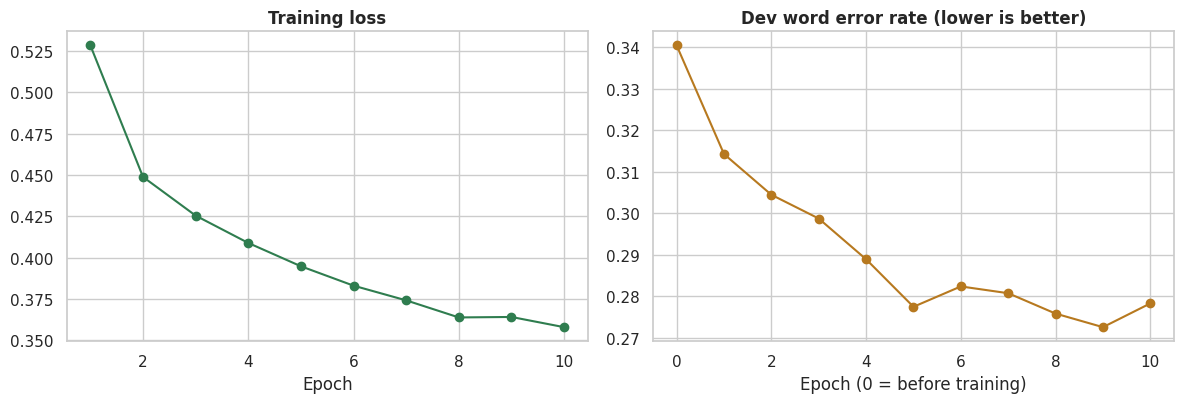

In [11]:
import random, math, time
import matplotlib.pyplot as plt
from transformers import get_linear_schedule_with_warmup

EPOCHS, BATCH, LR, WARMUP = 10, 4, 2e-4, 100
BEST_PATH = f"{DATA}/mms_kin_adapter_finetuned.pt"

# start again from the original adapter
with torch.no_grad():
    for n, p in asr_model.named_parameters():
        if n in orig_state:
            p.copy_(orig_state[n].to(p.device))
torch.cuda.empty_cache()

asr_model.config.layerdrop = 0.0
asr_model.config.ctc_zero_infinity = True
asr_model.config.ctc_loss_reduction = "mean"
asr_model.freeze_feature_encoder()

params = [p for p in asr_model.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.01)
steps_per_epoch = math.ceil(len(train_items) / BATCH)
sched = get_linear_schedule_with_warmup(opt, WARMUP, steps_per_epoch * EPOCHS)
scaler = torch.amp.GradScaler("cuda")

def make_batch(items):
    f = processor.feature_extractor([i["audio"] for i in items], sampling_rate=16000,
                                    return_tensors="pt", padding=True, return_attention_mask=True)
    L = max(len(i["labels"]) for i in items)
    y = torch.full((len(items), L), -100, dtype=torch.long)
    for k, i in enumerate(items):
        y[k, :len(i["labels"])] = torch.tensor(i["labels"])
    return f.input_values.to(DEVICE), f.attention_mask.to(DEVICE), y.to(DEVICE)

def dev_wer():
    asr_model.eval()
    with torch.autocast("cuda", dtype=torch.float16):
        hyps = [norm(transcribe(c["audio"]), False) for c in data["dev"]]
    refs = [norm(c["text"], False) for c in data["dev"]]
    pairs = [(r, h) for r, h in zip(refs, hyps) if r]
    asr_model.train()
    return jiwer.wer([p[0] for p in pairs], [p[1] for p in pairs])

best_wer = dev_wer()
best_state = {n: v.clone() for n, v in orig_state.items()}
history = [{"epoch": 0, "train_loss": None, "dev_WER": best_wer}]
print(f"before training: dev WER {best_wer:.3f}  ({steps_per_epoch} steps per epoch, {EPOCHS} epochs)")

step, oom, t0 = 0, 0, time.time()
for epoch in range(1, EPOCHS + 1):
    random.Random(epoch).shuffle(train_items)
    losses = []
    for b in range(0, len(train_items), BATCH):
        try:
            x, m, y = make_batch(train_items[b:b + BATCH])
            with torch.autocast("cuda", dtype=torch.float16):
                loss = asr_model(input_values=x, attention_mask=m, labels=y).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item()); step += 1
        except torch.cuda.OutOfMemoryError:
            oom += 1
            opt.zero_grad(set_to_none=True)
            torch.cuda.empty_cache()
            continue
        if step % 100 == 0:
            print(f"  step {step:5d} | loss {np.mean(losses[-100:]):.3f} | {time.time()-t0:.0f} s | skipped so far: {oom}")
    w = dev_wer()
    history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "dev_WER": w})
    mark = ""
    if w < best_wer:
        best_wer, mark = w, "  <- best so far, saved"
        best_state = {n: p.detach().cpu().clone() for n, p in asr_model.named_parameters() if p.requires_grad}
        torch.save(best_state, BEST_PATH)
    print(f"epoch {epoch}/{EPOCHS} | train loss {np.mean(losses):.3f} | dev WER {w:.3f}{mark}")

print(f"\ntraining took {(time.time()-t0)/60:.1f} min | batches skipped for memory: {oom}")
with torch.no_grad():
    for n, p in asr_model.named_parameters():
        if n in best_state:
            p.copy_(best_state[n].to(p.device))
asr_model.eval()
torch.save(best_state, BEST_PATH)
hist = pd.DataFrame(history); hist.to_csv(f"{DATA}/asr_training_history.csv", index=False)
print("best dev WER %.3f (started at %.3f). Adapter saved to Drive: mms_kin_adapter_finetuned.pt" % (best_wer, history[0]["dev_WER"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(hist.epoch[1:], hist.train_loss[1:], marker="o", color="#2f7d4f"); ax[0].set_title("Training loss", fontweight="bold"); ax[0].set_xlabel("Epoch")
ax[1].plot(hist.epoch, hist.dev_WER, marker="o", color="#b7791f"); ax[1].set_title("Dev word error rate (lower is better)", fontweight="bold"); ax[1].set_xlabel("Epoch (0 = before training)")
plt.tight_layout(); plt.savefig(f"{DATA}/asr_training_curves.png", dpi=200); plt.show()

In [12]:
after_test, after_table = evaluate_split("test")
after_test.to_csv(f"{DATA}/asr_after_test.csv", index=False, encoding="utf-8-sig")
after_table.round(4).to_csv(f"{DATA}/asr_after_summary.csv")

cmp = pd.DataFrame({"before WER": before_table.WER, "after WER": after_table.WER,
                    "before CER": before_table.CER, "after CER": after_table.CER}).round(3)
print("\n", cmp.to_string())

[test] 398 clips in 92 s
                   clips    WER    CER
ALL                398.0  0.278  0.057
rw_ag_tts_female   128.0  0.268  0.053
rw_ag_tts_female2   71.0  0.279  0.056
rw_ag_tts_male     124.0  0.289  0.064
rw_ag_tts_male2     75.0  0.277  0.055

  REF: Uretse uruteja, udusurira twangiza amababi akiri mato, imitwe y’amashami n’ururabyo. 
  HYP: uretse uruteja udusira twangiza amababo akira imato imitwe y'amashami n'ururabo

  REF: Indwara ya Tiripusi ya avoka
  HYP: indwara ya trpus yavoka

  REF: Kwirinda no kurwanya kirabiranya yo muri puwavuro
  HYP: kwirinda no kurwanya kiraberanyi yo muri powavuro

  REF: Akimirizi ( grlle à reine )
  HYP: akimirizi gilila rein

  REF: Ibimenyetso bya virusi ni ibi bikurikira : kugwingira kw’igihinga, kwikunja kw’amababi, kuma ibice by’amababi n’uruti, kubemba kw’amababi.
  HYP: ibimenyetso bya virusi ni ibi bikurikira kugwingira kw'igihingwa kwikunja kw'amababi kwuma ibice by'amababi n'uruti kubemba kw'amababi

  REF: Zikomoka mu Ubu

clips compared: 398


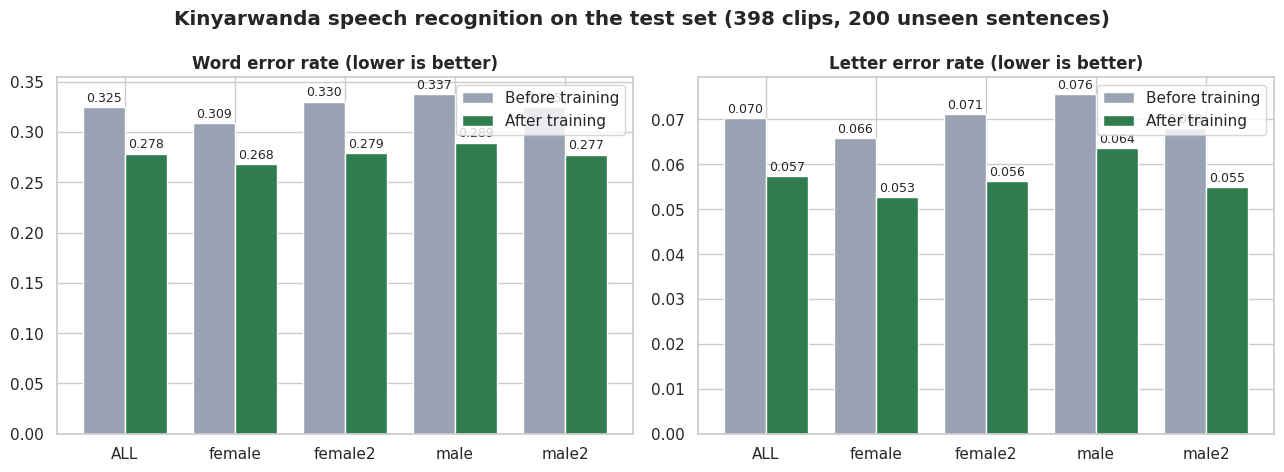

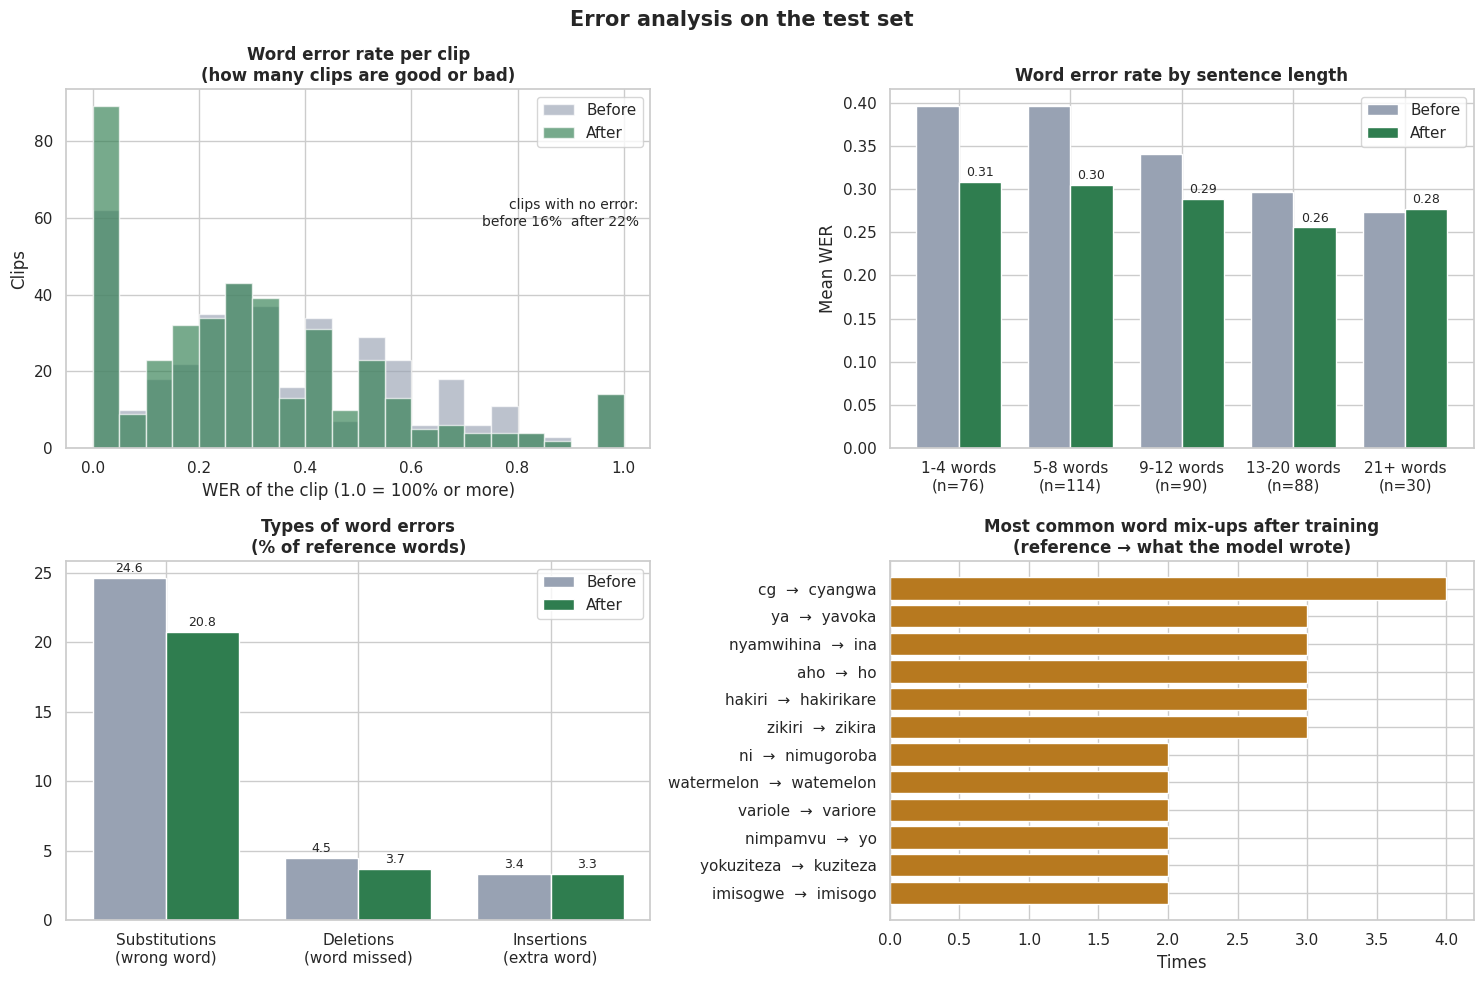


Top word mix-ups: ['cg->cyangwa (4)', 'ya->yavoka (3)', 'nyamwihina->ina (3)', 'aho->ho (3)', 'hakiri->hakirikare (3)', 'zikiri->zikira (3)', 'ni->nimugoroba (2)', 'watermelon->watemelon (2)']
saved: asr_before_after.png, asr_error_analysis.png, asr_examples_improved.csv, asr_examples_worst.csv


In [13]:
!pip install -q jiwer
import os
from google.colab import drive
if not os.path.isdir("/content/drive/MyDrive"):
    drive.mount("/content/drive")
DATA = "/content/drive/MyDrive/Mfasha chatbot/data"

import pandas as pd, numpy as np, matplotlib.pyplot as plt, jiwer, collections
GREEN, GREY, AMBER, BLUE = "#2f7d4f", "#98a2b3", "#b7791f", "#1b73c0"

b = pd.read_csv(f"{DATA}/asr_before_test.csv").fillna("")
a = pd.read_csv(f"{DATA}/asr_after_test.csv").fillna("")
df = b[["set", "id", "ref", "ref_l", "hyp", "hyp_l"]].merge(
    a[["set", "id", "hyp", "hyp_l"]], on=["set", "id"], suffixes=("_b", "_a"))
df["wer_b"] = [jiwer.wer(r, h) for r, h in zip(df.ref_l, df.hyp_l_b)]
df["wer_a"] = [jiwer.wer(r, h) for r, h in zip(df.ref_l, df.hyp_l_a)]
df["nwords"] = df.ref_l.str.split().str.len()
print("clips compared:", len(df))

# ---------- Figure 1: before vs after, overall and per voice set ----------
bs = pd.read_csv(f"{DATA}/asr_before_summary.csv", index_col=0)
as_ = pd.read_csv(f"{DATA}/asr_after_summary.csv", index_col=0)
names = [i.replace("rw_ag_tts_", "") for i in bs.index]
x = np.arange(len(names)); w = 0.38
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for k, (col, title) in enumerate([("WER", "Word error rate (lower is better)"),
                                  ("CER", "Letter error rate (lower is better)")]):
    b1 = ax[k].bar(x - w/2, bs[col], w, label="Before training", color=GREY)
    b2 = ax[k].bar(x + w/2, as_[col], w, label="After training", color=GREEN)
    ax[k].bar_label(b1, fmt="%.3f", padding=2, fontsize=9)
    ax[k].bar_label(b2, fmt="%.3f", padding=2, fontsize=9)
    ax[k].set_xticks(x); ax[k].set_xticklabels(names); ax[k].set_title(title, fontweight="bold"); ax[k].legend()
plt.suptitle("Kinyarwanda speech recognition on the test set (398 clips, 200 unseen sentences)", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{DATA}/asr_before_after.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Figure 2: error analysis ----------
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# (a) distribution of WER per clip
bins = np.linspace(0, 1.0, 21)
ax[0, 0].hist(df.wer_b.clip(upper=1), bins=bins, alpha=0.65, color=GREY, label="Before", edgecolor="white")
ax[0, 0].hist(df.wer_a.clip(upper=1), bins=bins, alpha=0.65, color=GREEN, label="After", edgecolor="white")
ax[0, 0].set_title("Word error rate per clip\n(how many clips are good or bad)", fontweight="bold")
ax[0, 0].set_xlabel("WER of the clip (1.0 = 100% or more)"); ax[0, 0].set_ylabel("Clips"); ax[0, 0].legend()
perfect_b, perfect_a = (df.wer_b == 0).mean() * 100, (df.wer_a == 0).mean() * 100
ax[0, 0].text(0.98, 0.62, f"clips with no error:\nbefore {perfect_b:.0f}%  after {perfect_a:.0f}%",
              transform=ax[0, 0].transAxes, ha="right", fontsize=10)

# (b) WER by sentence length
df["len_bin"] = pd.cut(df.nwords, [0, 4, 8, 12, 20, 200], labels=["1-4", "5-8", "9-12", "13-20", "21+"])
g = df.groupby("len_bin", observed=True).agg(before=("wer_b", "mean"), after=("wer_a", "mean"), clips=("wer_a", "size"))
xx = np.arange(len(g))
b1 = ax[0, 1].bar(xx - w/2, g.before, w, color=GREY, label="Before")
b2 = ax[0, 1].bar(xx + w/2, g.after, w, color=GREEN, label="After")
ax[0, 1].bar_label(b2, fmt="%.2f", padding=2, fontsize=9)
ax[0, 1].set_xticks(xx); ax[0, 1].set_xticklabels([f"{i} words\n(n={n})" for i, n in zip(g.index, g.clips)])
ax[0, 1].set_title("Word error rate by sentence length", fontweight="bold"); ax[0, 1].set_ylabel("Mean WER"); ax[0, 1].legend()

# (c) error types
def parts(refs, hyps):
    o = jiwer.process_words(list(refs), list(hyps))
    n = o.hits + o.substitutions + o.deletions
    return [100 * o.substitutions / n, 100 * o.deletions / n, 100 * o.insertions / n]
pb, pa = parts(df.ref_l, df.hyp_l_b), parts(df.ref_l, df.hyp_l_a)
xx = np.arange(3)
b1 = ax[1, 0].bar(xx - w/2, pb, w, color=GREY, label="Before")
b2 = ax[1, 0].bar(xx + w/2, pa, w, color=GREEN, label="After")
ax[1, 0].bar_label(b1, fmt="%.1f", padding=2, fontsize=9); ax[1, 0].bar_label(b2, fmt="%.1f", padding=2, fontsize=9)
ax[1, 0].set_xticks(xx)
ax[1, 0].set_xticklabels(["Substitutions\n(wrong word)", "Deletions\n(word missed)", "Insertions\n(extra word)"])
ax[1, 0].set_title("Types of word errors\n(% of reference words)", fontweight="bold"); ax[1, 0].legend()

# (d) most common word mix-ups after training
o = jiwer.process_words(list(df.ref_l), list(df.hyp_l_a))
pairs = collections.Counter()
for rw, hw, al in zip(o.references, o.hypotheses, o.alignments):
    for ch in al:
        if ch.type == "substitute":
            for k in range(ch.ref_end_idx - ch.ref_start_idx):
                pairs[(rw[ch.ref_start_idx + k], hw[ch.hyp_start_idx + k])] += 1
top = pairs.most_common(12)[::-1]
ax[1, 1].barh([f"{r}  →  {h}" for (r, h), _ in top], [c for _, c in top], color=AMBER)
ax[1, 1].set_title("Most common word mix-ups after training\n(reference → what the model wrote)", fontweight="bold")
ax[1, 1].set_xlabel("Times")

plt.suptitle("Error analysis on the test set", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{DATA}/asr_error_analysis.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Examples tables ----------
cols = ["set", "ref", "hyp_b", "hyp_a", "wer_b", "wer_a"]
df.assign(gain=df.wer_b - df.wer_a).sort_values("gain", ascending=False).head(10)[cols] \
  .to_csv(f"{DATA}/asr_examples_improved.csv", index=False, encoding="utf-8-sig")
df.sort_values("wer_a", ascending=False).head(10)[cols] \
  .to_csv(f"{DATA}/asr_examples_worst.csv", index=False, encoding="utf-8-sig")

print("\nTop word mix-ups:", [f"{r}->{h} ({c})" for (r, h), c in pairs.most_common(8)])
print("saved: asr_before_after.png, asr_error_analysis.png, asr_examples_improved.csv, asr_examples_worst.csv")

In [14]:
import pandas as pd, re, jiwer
DATA = "/content/drive/MyDrive/Mfasha chatbot/data"

def nkey_of(t):
    t = t.lower().replace("\u2019", "'").replace("\u2018", "'")
    t = re.sub(r"[^\w' ]+", " ", t).replace("'", "")
    return re.sub(r"\s+", " ", t).strip()

def messy(t):
    return bool(re.search(r"[()/\[\]]", t)) or any(ord(ch) > 127 and ch not in "\u2019\u2018" for ch in t)

split = pd.read_csv(f"{DATA}/asr_split.csv")
train_n = {nkey_of(t) for t in split[split.split == "train"].text.astype(str)}

before = pd.read_csv(f"{DATA}/asr_before_test.csv").fillna("")
after = pd.read_csv(f"{DATA}/asr_after_test.csv").fillna("")

rows = []
for name, d_b, d_a in [("All test clips", before, after)]:
    pass
for label, keep in [("All test clips", lambda r: True),
                     ("Clean text only (no brackets, slashes, foreign letters)", lambda r: not messy(r)),
                     ("Clean and not in train", lambda r: (not messy(r)) and nkey_of(r) not in train_n)]:
    mb = before[before.ref.apply(keep)]
    ma = after[after.ref.apply(keep)]
    rows.append({"subset": label, "clips": len(ma),
                 "WER before": jiwer.wer(list(mb.ref_l), list(mb.hyp_l)),
                 "WER after": jiwer.wer(list(ma.ref_l), list(ma.hyp_l)),
                 "CER before": jiwer.cer(list(mb.ref_l), list(mb.hyp_l)),
                 "CER after": jiwer.cer(list(ma.ref_l), list(ma.hyp_l))})
res = pd.DataFrame(rows).set_index("subset").round(3)
print(res.to_string())
res.to_csv(f"{DATA}/asr_clean_subset_results.csv")

                                                         clips  WER before  WER after  CER before  CER after
subset                                                                                                      
All test clips                                             398       0.325      0.278       0.070      0.057
Clean text only (no brackets, slashes, foreign letters)    328       0.300      0.255       0.055      0.044
Clean and not in train                                     326       0.301      0.255       0.055      0.044
